# 01. Annotator and Visuals

This notebook runs an annotator to label tumor vs non-tumor data.

We also visually inspect the dataset.

In [1]:
import sys, pathlib

# calculate project root relative to this notebook
PROJECT_ROOT = pathlib.Path().resolve().parent  # notebooks/.. = project root
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.annotator import ClinicalAnnotator

annotator = ClinicalAnnotator(
    data_path="../data/processed/glioma_dataset.h5",
    algorithm="gmm",       
    pca_variance=0.99,     
    spatial_weight=2.0     
)
annotator.annotate() # This writes 'y_tumor' to the HDF5!

🚀 Starting Spatio-Spectral Annotation (Algorithm: GMM)...
📂 Found 58 unique slides to process.


Clustering Slides:  17%|█▋        | 10/58 [00:18<01:21,  1.70s/it]c:\Users\Andrei\anaconda3\envs\glioma\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(
Clustering Slides:  19%|█▉        | 11/58 [00:18<01:03,  1.35s/it]c:\Users\Andrei\anaconda3\envs\glioma\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=7.
  warnings.warn(
Clustering Slides:  38%|███▊      | 22/58 [00:33<00:44,  1.23s/it]c:\Users\Andrei\anaconda3\envs\glioma\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than availab


💾 Writing 'y_tumor' labels directly to HDF5...
✅ Annotation Complete!
📊 Final Dataset: 53508 Tumor spectra (27.1%) out of 197596 total tissue spectra.



🔬 Generating Visual Inspection Maps...


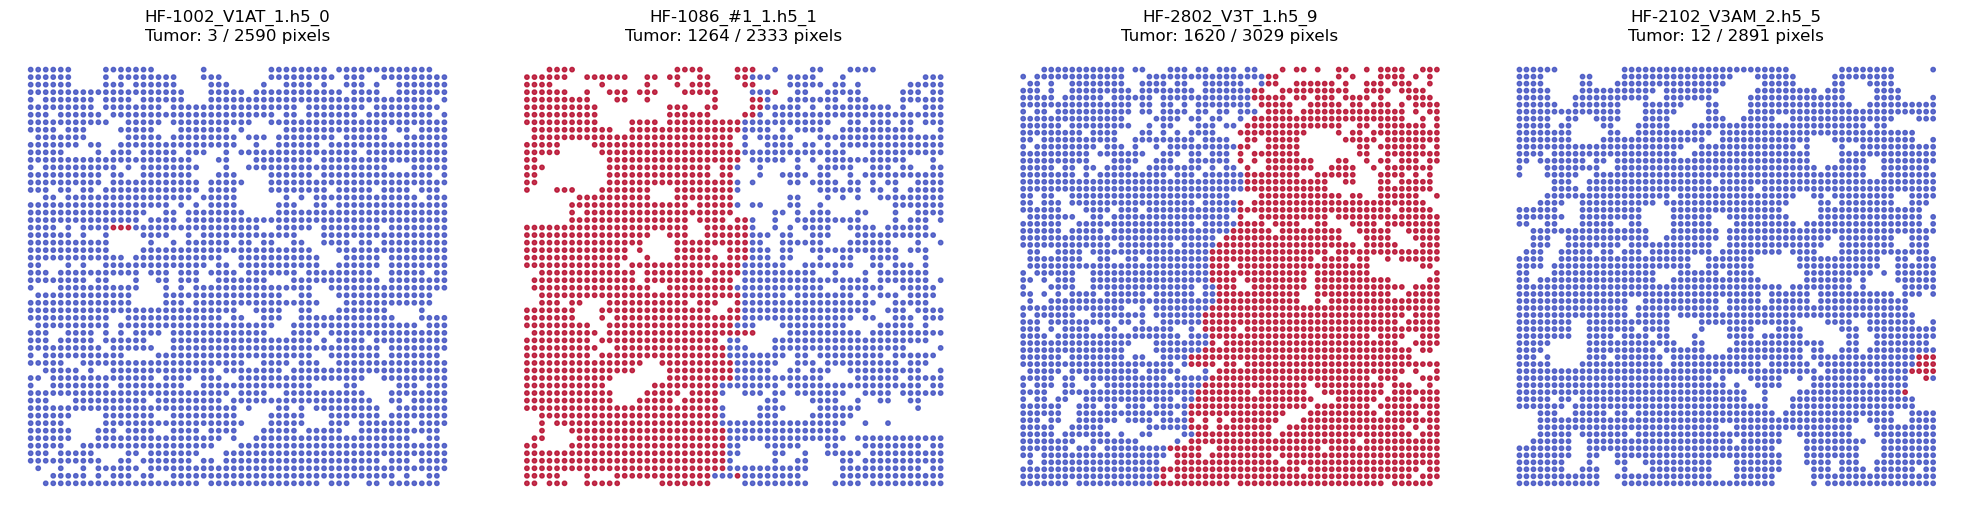

In [2]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

# --- 2. Visual Inspection ---
print("\n🔬 Generating Visual Inspection Maps...")
with h5py.File("../data/processed/glioma_dataset.h5", "r") as f:
    coords = f['coords'][:]
    y_tumor = f['y_tumor'][:]
    
    raw_samples = f['sample_ids'][:]
    if isinstance(raw_samples[0], (bytes, np.bytes_)):
        samples = np.char.decode(raw_samples.astype('S'), 'utf-8')
    else:
        samples = raw_samples.astype(str)

    unique_samples = np.unique(samples)
    
    # Pick 4 random slides to inspect
    np.random.seed(42) 
    test_slides = np.random.choice(unique_samples, 4, replace=False)
    
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    
    for ax, slide in zip(axes, test_slides):
        mask = (samples == slide)
        c_slide = coords[mask]
        l_slide = y_tumor[mask]
        
        # Plot: Blue=Healthy (0), Red=Tumor (1)
        scatter = ax.scatter(c_slide[:, 0], c_slide[:, 1], c=l_slide, cmap='coolwarm', s=10, alpha=0.8)
        
        # Invert Y axis so it matches standard image/microscope viewing
        ax.invert_yaxis()
        ax.set_aspect('equal')
        ax.set_title(f"{slide}\nTumor: {np.sum(l_slide)} / {len(l_slide)} pixels")
        ax.axis('off')

    plt.tight_layout()
    plt.show()


🔬 Generating Visual Inspection Maps...


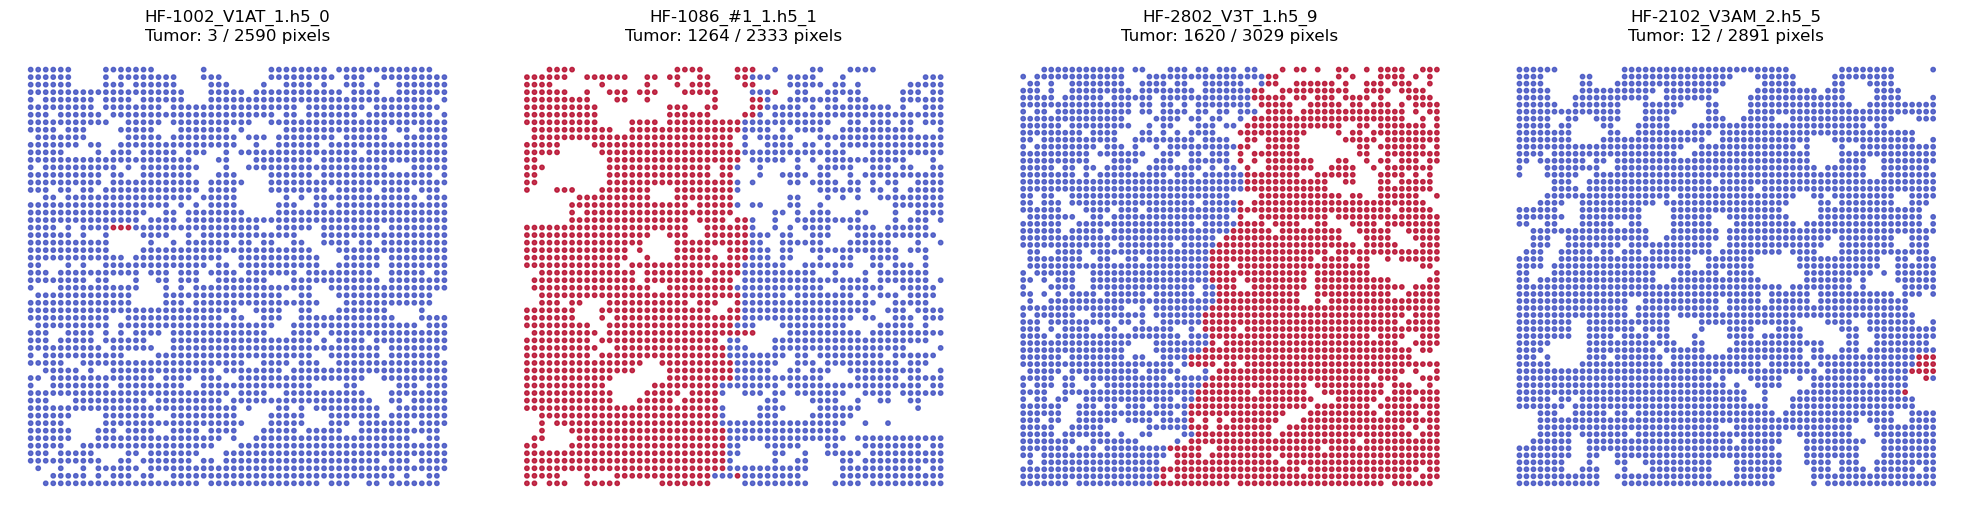

In [3]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

# --- 2. Visual Inspection ---
print("\n🔬 Generating Visual Inspection Maps...")
with h5py.File("../data/processed/glioma_dataset.h5", "r") as f:
    coords = f['coords'][:]
    y_tumor = f['y_tumor'][:]
    
    raw_samples = f['sample_ids'][:]
    if isinstance(raw_samples[0], (bytes, np.bytes_)):
        samples = np.char.decode(raw_samples.astype('S'), 'utf-8')
    else:
        samples = raw_samples.astype(str)

    unique_samples = np.unique(samples)
    
    # Pick 4 random slides to inspect
    np.random.seed(42) 
    test_slides = np.random.choice(unique_samples, 4, replace=False)
    
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    
    for ax, slide in zip(axes, test_slides):
        mask = (samples == slide)
        c_slide = coords[mask]
        l_slide = y_tumor[mask]
        
        # Plot: Blue=Healthy (0), Red=Tumor (1)
        scatter = ax.scatter(c_slide[:, 0], c_slide[:, 1], c=l_slide, cmap='coolwarm', s=10, alpha=0.8)
        
        # Invert Y axis so it matches standard image/microscope viewing
        ax.invert_yaxis()
        ax.set_aspect('equal')
        ax.set_title(f"{slide}\nTumor: {np.sum(l_slide)} / {len(l_slide)} pixels")
        ax.axis('off')

    plt.tight_layout()
    plt.show()